# 03 · Flan-T5 quadruple generation

Flan-T5-base is fine-tuned to read a review sentence and generate all of its (aspect, category, opinion, sentiment) quadruples as text, which is parsed back into tuples and scored with exact-match micro-F1.

| Experiment | Training data | Test data | Seeds |
|---|---|---|---|
| `all_domains` | All five domains | All five domains | 42, 153, 650 |
| `in_domain` | One domain (one model per domain) | The same domain | 42, 153, 650 |
| `cross_laptop_restaurant` | Laptop + Restaurant | All five domains | 42 |
| `leave_one_out` | Four domains (one model per held-out domain) | The held-out domain | 42 |

Each training cell can be run on its own; completed runs are skipped.

In [11]:
PROJECT_DIR = "/content/drive/MyDrive/aspect-insight"

In [12]:
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PROJECT_DIR = os.path.abspath("..")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/aspect-insight


In [13]:
!pip -q install -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB


## Training

In [14]:
!python scripts/train_t5.py --experiments all_domains

Device: NVIDIA A100-SXM4-40GB
[all_domains/model seed 42] already complete, skipped
[all_domains/model seed 153] already complete, skipped
[all_domains/model seed 650] already complete, skipped


In [15]:
!python scripts/train_t5.py --experiments in_domain

Device: NVIDIA A100-SXM4-40GB
[in_domain/Books seed 42] already complete, skipped
[in_domain/Clothing seed 42] already complete, skipped
[in_domain/Hotel seed 42] already complete, skipped
[in_domain/Laptop seed 42] already complete, skipped
[in_domain/Restaurant seed 42] already complete, skipped
[in_domain/Books seed 153] already complete, skipped
[in_domain/Clothing seed 153] already complete, skipped
[in_domain/Hotel seed 153] already complete, skipped
[in_domain/Laptop seed 153] already complete, skipped
[in_domain/Restaurant seed 153] already complete, skipped
[in_domain/Books seed 650] already complete, skipped
[in_domain/Clothing seed 650] already complete, skipped
[in_domain/Hotel seed 650] already complete, skipped
[in_domain/Laptop seed 650] already complete, skipped
[in_domain/Restaurant seed 650] already complete, skipped


In [6]:
!python scripts/train_t5.py --experiments cross_laptop_restaurant leave_one_out

Device: NVIDIA A100-SXM4-40GB
[cross_laptop_restaurant/model seed 42] train 6,485 | dev 915 | test 3,583 sentences (Laptop, Restaurant -> Books, Clothing, Hotel, Laptop, Restaurant)
Loading weights: 100% 282/282 [00:00<00:00, 5546.07it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
    epoch 1: loss 0.6302 | 62.5s
    epoch 2: loss 0.1805 | 61.5s
    epoch 3: loss 0.1322 | 63.5s
    epoch 4: loss 0.1067 | dev ACOS F1 0.4900 | 63.8s
    epoch 5: loss 0.0861 | dev ACOS F1 0.4940 | 62.1s
    epoch 6: loss 0.0712 | dev ACOS F1 0.4951 | 62.0s
    epoch 7: loss 0.0596 | dev ACOS F1 0.4881 | 61.9s
    epoch 8: loss 0.0501 | dev ACOS F1 0.4782 | 62.0s
    epoch 9: loss 0.0410 | dev ACOS F1 0.4935 | 61.9s
    epoch 10: loss 0.0330 | dev ACOS F1 0.5022 

## Evaluation

In [7]:
!python scripts/evaluate_generators.py --runs-dir outputs/runs/t5 --out-dir outputs/results/t5 --label "Flan-T5-base"

# Flan-T5-base: quadruple extraction results

Micro-F1 (%) with exact matching. Mean ± standard deviation over seeds where several seeds were run.

## Comparison with published results (ACOS, Table 9 of the MEMD-ABSA paper)

| Domain | Best published | T5-Paraphrase | T5-index | Ours: per-domain models | Ours: one model, all domains |
|---|---|---|---|---|---|
| Books | 41.71 (T5-index) | 39.00 | 41.71 | 39.00 ± 0.77 | 38.71 ± 2.39 |
| Clothing | 41.26 (T5-Paraphrase) | 41.26 | 37.55 | 40.42 ± 0.61 | 39.32 ± 1.59 |
| Hotel | 69.22 (T5-index) | 66.89 | 69.22 | 65.54 ± 1.56 | 67.16 ± 1.94 |
| Restaurant | 56.49 (T5-index) | 56.31 | 56.49 | 55.53 ± 0.68 | 54.59 ± 0.50 |
| Laptop | 43.57 (T5-Paraphrase) | 43.57 | 40.38 | 33.97 ± 0.77 | 22.73 ± 0.77 |

## Comparison with published results (AOS, Table 9)

| Domain | Best published | Ours: per-domain models | Ours: one model, all domains |
|---|---|---|---|
| Books | 53.46 (T5-index) | 48.54 ± 0.59 | 51.40 ± 2.49 |
| Clothing | 69.63 (T5-inde

In [8]:
!python scripts/decoding_ablation.py --model-dir outputs/runs/t5/all_domains/model/seed42/model --out-dir outputs/results/t5

Loading weights: 100% 282/282 [00:00<00:00, 2200.59it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
Device: NVIDIA A100-SXM4-40GB | 3,583 test sentences
Greedy                                                  ACOS F1 47.18 | 35.5 ms/sentence
Beam search (4 beams)                                   ACOS F1 47.22 | 45.3 ms/sentence
Sampling, T=0.7, top-p=0.9                              ACOS F1 46.42 | 36.3 ms/sentence
Sampling, T=1.0, top-p=1.0                              ACOS F1 44.79 | 36.8 ms/sentence
Self-consistency (5 samples, T=0.7, majority vote)      ACOS F1 47.70 | 183.3 ms/sentence


In [9]:
from IPython.display import Image, Markdown, display

RESULTS = "outputs/results/t5"
display(Markdown(open(f"{RESULTS}/results.md", encoding="utf-8").read()))
display(Markdown(open(f"{RESULTS}/decoding_ablation.md", encoding="utf-8").read()))

# Flan-T5-base: quadruple extraction results

Micro-F1 (%) with exact matching. Mean ± standard deviation over seeds where several seeds were run.

## Comparison with published results (ACOS, Table 9 of the MEMD-ABSA paper)

| Domain | Best published | T5-Paraphrase | T5-index | Ours: per-domain models | Ours: one model, all domains |
|---|---|---|---|---|---|
| Books | 41.71 (T5-index) | 39.00 | 41.71 | 39.00 ± 0.77 | 38.71 ± 2.39 |
| Clothing | 41.26 (T5-Paraphrase) | 41.26 | 37.55 | 40.42 ± 0.61 | 39.32 ± 1.59 |
| Hotel | 69.22 (T5-index) | 66.89 | 69.22 | 65.54 ± 1.56 | 67.16 ± 1.94 |
| Restaurant | 56.49 (T5-index) | 56.31 | 56.49 | 55.53 ± 0.68 | 54.59 ± 0.50 |
| Laptop | 43.57 (T5-Paraphrase) | 43.57 | 40.38 | 33.97 ± 0.77 | 22.73 ± 0.77 |

## Comparison with published results (AOS, Table 9)

| Domain | Best published | Ours: per-domain models | Ours: one model, all domains |
|---|---|---|---|
| Books | 53.46 (T5-index) | 48.54 ± 0.59 | 51.40 ± 2.49 |
| Clothing | 69.63 (T5-index) | 68.93 ± 1.11 | 68.72 ± 0.78 |
| Hotel | 77.98 (T5-index) | 74.08 ± 1.63 | 76.81 ± 1.14 |
| Restaurant | 65.12 (T5-index) | 61.06 ± 0.82 | 62.49 ± 0.15 |
| Laptop | 67.88 (T5-Paraphrase) | 52.72 ± 0.28 | 54.67 ± 0.78 |

## One model for all domains: every sub-task (all test sentences)

| Model | AE | ASPE | CS | AOS | ACS | ACOS | ACOS precision | ACOS recall |
|---|---|---|---|---|---|---|---|---|
| one model, all domains | 78.89 ± 0.55 | 74.44 ± 0.32 | 62.93 ± 0.63 | 63.01 ± 0.75 | 53.75 ± 0.71 | 46.62 ± 0.92 | 46.74 ± 0.28 | 46.52 ± 1.55 |

## Categories from the wrong domain (single models)

Share of predicted quadruples whose category exists only in another domain, and ACOS F1 before and after such quadruples are removed.

| Model | Domain | Wrong-domain categories (%) | ACOS F1 | ACOS F1, wrong-domain removed |
|---|---|---|---|---|
| one model, all domains | Books | 4.37 ± 0.40 | 38.71 ± 2.39 | 39.56 ± 2.41 |
| one model, all domains | Clothing | 6.75 ± 1.02 | 39.32 ± 1.59 | 40.69 ± 1.61 |
| one model, all domains | Hotel | 3.37 ± 0.82 | 67.16 ± 1.94 | 68.30 ± 1.72 |
| one model, all domains | Restaurant | 3.65 ± 0.77 | 54.59 ± 0.50 | 55.59 ± 0.30 |
| one model, all domains | Laptop | 26.28 ± 1.61 | 22.73 ± 0.77 | 26.20 ± 0.87 |

## Transfer to other domains (ACOS F1)

| Training data | Books | Clothing | Hotel | Restaurant | Laptop |
|---|---|---|---|---|---|
| Trained on the same domain | 39.00 ± 0.77 | 40.42 ± 0.61 | 65.54 ± 1.56 | 55.53 ± 0.68 | 33.97 ± 0.77 |
| Trained on all five domains | 38.71 ± 2.39 | 39.32 ± 1.59 | 67.16 ± 1.94 | 54.59 ± 0.50 | 22.73 ± 0.77 |
| Trained on Laptop + Restaurant | 5.80 | 1.29 | 21.18 | 57.16 | 27.19 |
| Trained on the other four domains | 0.93 | 2.56 | 21.53 | 10.71 | 0.18 |

## Transfer to other domains (AOS F1)

| Training data | Books | Clothing | Hotel | Restaurant | Laptop |
|---|---|---|---|---|---|
| Trained on the same domain | 48.54 ± 0.59 | 68.93 ± 1.11 | 74.08 ± 1.63 | 61.06 ± 0.82 | 52.72 ± 0.28 |
| Trained on all five domains | 51.40 ± 2.49 | 68.72 ± 0.78 | 76.81 ± 1.14 | 62.49 ± 0.15 | 54.67 ± 0.78 |
| Trained on Laptop + Restaurant | 34.07 | 50.04 | 59.45 | 62.70 | 53.66 |
| Trained on the other four domains | 38.61 | 53.44 | 64.80 | 52.11 | 48.43 |

### Leave-one-domain-out vs the paper (AOS, sentences with explicit elements only; approximate)

| Held-out domain | Paper (T5-Paraphrase) | Ours |
|---|---|---|
| Books | 51.78 | 42.74 |
| Clothing | 60.39 | 55.36 |
| Hotel | 72.60 | 66.81 |
| Restaurant | 61.47 | 52.20 |
| Laptop | 61.77 | 52.39 |

## ACOS recall by element type (one model, all domains)

| Gold quadruples with | Count | Recall (%) |
|---|---|---|
| explicit aspect | 4,098 | 50.49 ± 1.55 |
| explicit opinion | 4,384 | 51.67 ± 1.13 |
| implicit aspect | 1,381 | 34.47 ± 1.62 |
| implicit opinion | 1,095 | 25.54 ± 3.22 |

## Error analysis (all_domains, seed 42)

2,887 gold quadruples were not produced exactly; 1,309 predictions had no matching gold quadruple.

| Missed because of | Count | Share |
|---|---|---|
| category | 764 | 26.5% |
| opinion | 336 | 11.6% |
| sentiment | 70 | 2.4% |
| aspect found, several elements wrong | 445 | 15.4% |
| aspect missed | 1,272 | 44.1% |

## Runs

| Experiment | Run | Seed | Best epoch | Train (min) | ms/sentence | Malformed segments |
|---|---|---|---|---|---|---|
| all_domains | model | 42 | 12 | 44.0 | 34.44 | 1 |
| all_domains | model | 153 | 5 | 25.2 | 31.9 | 3 |
| all_domains | model | 650 | 11 | 43.8 | 33.63 | 1 |
| cross_laptop_restaurant | model | 42 | 10 | 21.1 | 38.11 | 3 |
| in_domain | Books | 42 | 5 | 4.0 | 43.89 | 3 |
| in_domain | Books | 153 | 5 | 3.8 | 30.58 | 0 |
| in_domain | Books | 650 | 4 | 3.4 | 34.91 | 0 |
| in_domain | Clothing | 42 | 8 | 4.3 | 30.43 | 0 |
| in_domain | Clothing | 153 | 11 | 5.5 | 29.22 | 0 |
| in_domain | Clothing | 650 | 15 | 7.1 | 26.69 | 0 |
| in_domain | Hotel | 42 | 7 | 6.1 | 37.09 | 0 |
| in_domain | Hotel | 153 | 4 | 4.3 | 36.37 | 1 |
| in_domain | Hotel | 650 | 7 | 6.2 | 33.65 | 0 |
| in_domain | Laptop | 42 | 4 | 4.9 | 36.25 | 1 |
| in_domain | Laptop | 153 | 6 | 6.2 | 31.86 | 0 |
| in_domain | Laptop | 650 | 8 | 7.7 | 33.08 | 2 |
| in_domain | Restaurant | 42 | 7 | 9.3 | 31.51 | 0 |
| in_domain | Restaurant | 153 | 8 | 10.2 | 38.96 | 0 |
| in_domain | Restaurant | 650 | 9 | 11.0 | 38.27 | 0 |
| leave_one_out | without_Books | 42 | 10 | 34.3 | 33.76 | 0 |
| leave_one_out | without_Clothing | 42 | 9 | 33.1 | 29.44 | 0 |
| leave_one_out | without_Hotel | 42 | 6 | 22.7 | 38.94 | 1 |
| leave_one_out | without_Laptop | 42 | 11 | 35.6 | 30.08 | 0 |
| leave_one_out | without_Restaurant | 42 | 9 | 27.9 | 41.0 | 0 |


# Decoding strategies

3,583 test sentences, model `model`.

| Strategy | ACOS F1 | Precision | Recall | AOS F1 | Malformed segments | ms/sentence |
|---|---|---|---|---|---|---|
| Greedy | 47.18 | 46.99 | 47.38 | 63.18 | 1.0 | 35.5 |
| Beam search (4 beams) | 47.22 | 46.67 | 47.78 | 63.24 | 1.0 | 45.3 |
| Sampling, T=0.7, top-p=0.9 | 46.42 | 46.20 | 46.65 | 62.81 | 1.0 | 36.3 |
| Sampling, T=1.0, top-p=1.0 | 44.79 | 44.51 | 45.07 | 61.51 | 2.0 | 36.8 |
| Self-consistency (5 samples, T=0.7, majority vote) | 47.70 | 48.42 | 46.99 | 63.15 | 1.0 | 183.3 |


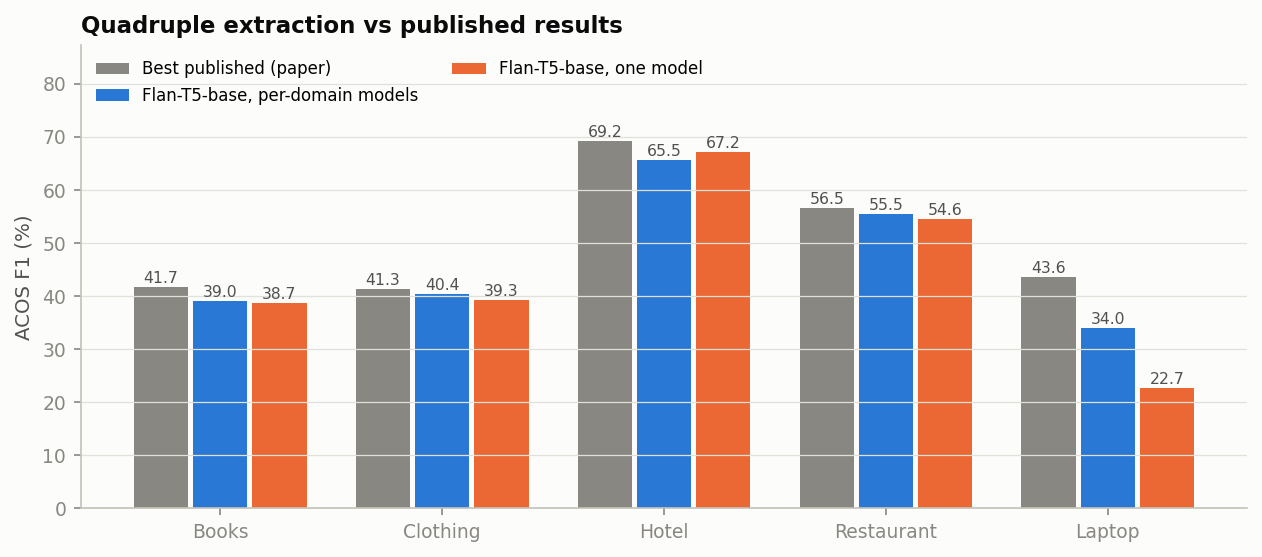

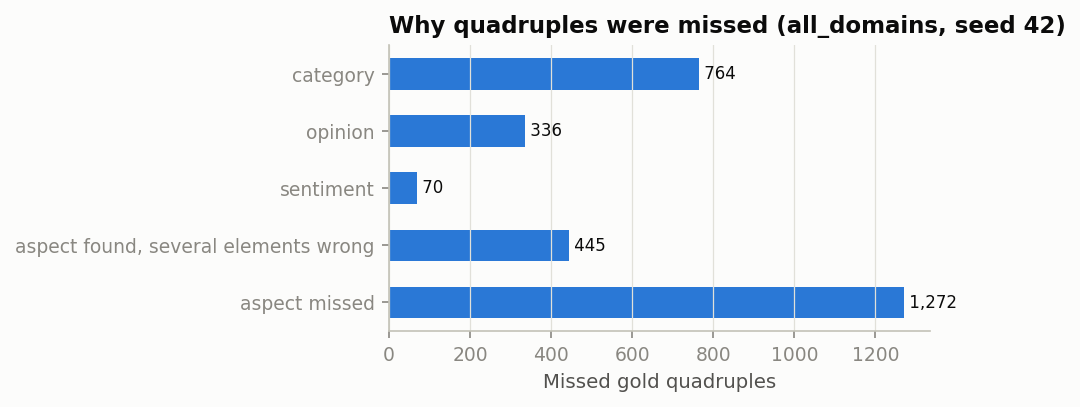

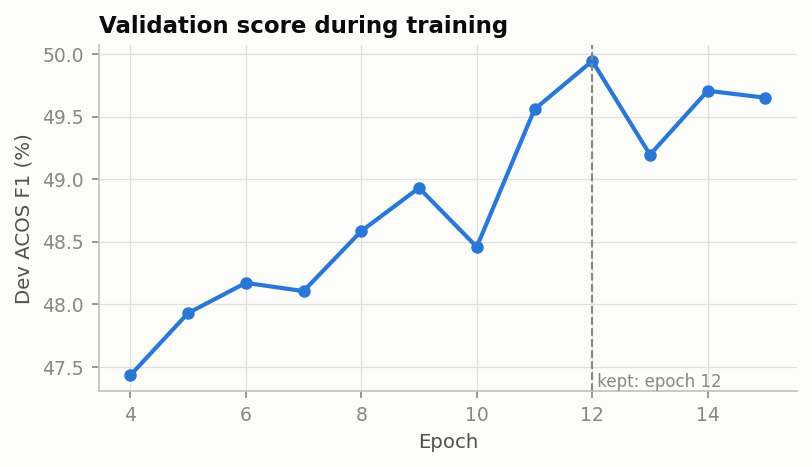

In [10]:
for name in ["acos_vs_published", "error_types", "dev_curve"]:
    display(Image(f"{RESULTS}/figures/{name}.png"))